# Example use of non-cartesian MORSE

## Load saved data
Plot data to ensure correct sorting

(7200, 3)
(32, 7200)


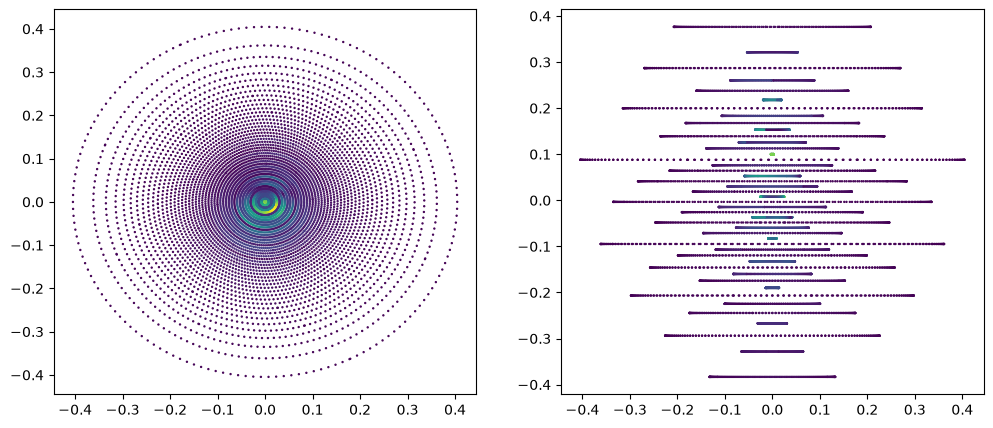

In [5]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

data_path = Path('test_data')

trajectory = np.load(data_path / 'traj.npy')
data = np.load(data_path / 'data.npy')

print(trajectory.shape)
print(data.shape)

fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(
    trajectory[:, 0],
    trajectory[:, 1],
    s=0.5,
    c=np.abs(data[0, :]))
axes[1].scatter(
    trajectory[:, 0],
    trajectory[:, 2],
    s=0.5,
    c=np.abs(data[0, :]))
plt.show()

In [8]:
trajectory.max(axis=0)

array([0.40460061, 0.4045356 , 0.37633996])

100%|██████████| 10/10 [00:04<00:00,  2.06it/s]


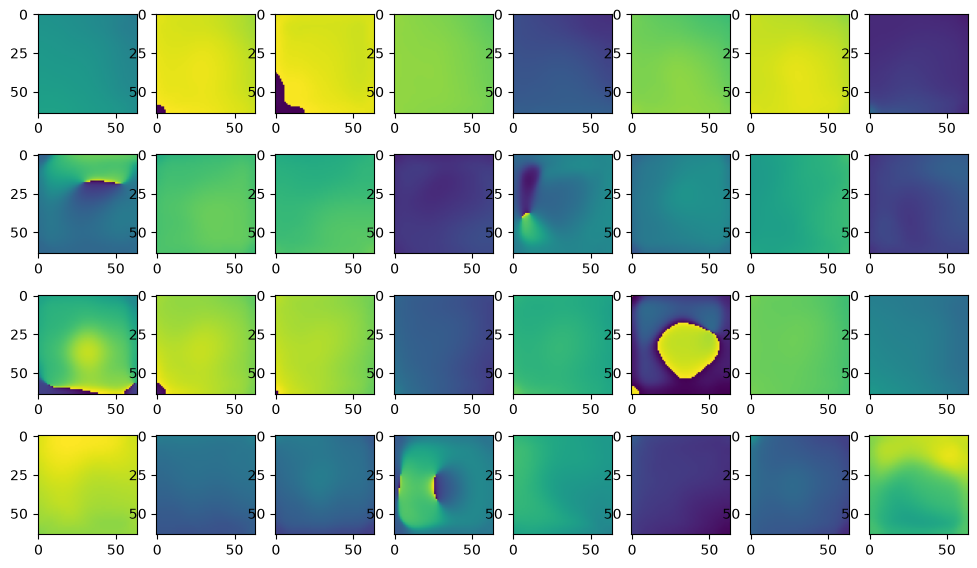

In [14]:
from morse_pi import morse_pi

sens = morse_pi(
    data=data,
    trajectory=trajectory,
    resolution=(64,64,8),
    backend='torchkbnufft-cpu',
) 


ref_dx = 0
_, axes = plt.subplots(4,8, figsize=(12, 7))
for idx, ax in enumerate(axes.ravel()):
    # ax.imshow(np.abs(sens[..., 4, idx, ref_dx]))
    ax.imshow(np.angle(sens[..., 4, idx, ref_dx]), vmin=-np.pi, vmax=np.pi)

plt.show()